# Day 1 · 이론 2 추가 실습 — k-최근접 이웃 회귀

* 추가 실습 - A : KNN 회귀의 예측값 직접 계산하기 
* 추가 실습 - B : 이웃 수에 따른 모델 성능 비교하기 
* 추가 실습 - C : 이웃 수에 따른 KNN 회귀 예측선 시각화하기 

## 0. 데이터 준비 (교재 3-1과 동일)

농어 56마리의 길이와 무게를 준비하고, `random_state=42`로 훈련 42마리·테스트 14마리로 나눈 뒤 입력을 2차원 배열로 바꿉니다.

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split

perch_length = np.array([
    8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0
])

perch_weight = np.array([
    5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0
])

train_input, test_input, train_target, test_target = train_test_split(
    perch_length, perch_weight, random_state=42
)

train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)

print("훈련 입력:", train_input.shape, "테스트 입력:", test_input.shape)

훈련 입력: (42, 1) 테스트 입력: (14, 1)


## [추가 실습 -A] KNN 회귀의 예측값 직접 계산하기

**실습 목표**: KNN 회귀 모델이 가까운 이웃의 실제 무게를 평균 내어 예측한다는 원리를 코드로 확인합니다.

길이가 30cm인 새로운 농어를 입력하고, 모델이 선택한 이웃 5마리를 확인합니다.

### 1단계. 가까운 이웃 5마리 찾기

`kneighbors()`는 새로운 입력에서 가까운 이웃까지의 거리와 훈련 데이터에서의 인덱스를 반환합니다.

In [2]:
from sklearn.neighbors import KNeighborsRegressor

# 이웃 5마리를 참고하는 모델
knr_manual = KNeighborsRegressor(n_neighbors=5)
knr_manual.fit(train_input, train_target)

# 길이 30cm인 농어
new_fish = np.array([[30.0]])

# 가까운 이웃 찾기
distances, indexes = knr_manual.kneighbors(new_fish)

# 이웃의 길이와 실제 무게
neighbor_lengths = train_input[indexes[0], 0]
neighbor_weights = train_target[indexes[0]]

for length, weight, distance in zip(
    neighbor_lengths, neighbor_weights, distances[0]
):
    print(
        f"길이 {length:4.1f}cm | "
        f"무게 {weight:5.1f}g | "
        f"거리 {distance:4.1f}cm"
    )

길이 28.7cm | 무게 300.0g | 거리  1.3cm
길이 27.5cm | 무게 265.0g | 거리  2.5cm
길이 27.5cm | 무게 260.0g | 거리  2.5cm
길이 32.8cm | 무게 514.0g | 거리  2.8cm
길이 26.5cm | 무게 218.0g | 거리  3.5cm


### 2단계. 이웃의 평균 무게와 모델 예측값 비교하기

In [3]:
# 선택된 이웃의 실제 무게 평균
manual_prediction = neighbor_weights.mean()

# 모델의 예측 결과
model_prediction = knr_manual.predict(new_fish)[0]

print(f"직접 계산한 평균: {manual_prediction:.2f}g")
print(f"모델 예측값: {model_prediction:.2f}g")

직접 계산한 평균: 311.40g
모델 예측값: 311.40g


### 3단계. 학생 응용 실습

위의 `new_fish` 값을 `[[35.0]]`으로 변경하고 1단계·2단계 셀을 다시 실행해 보세요.

* **완료 확인**: 직접 계산한 평균과 모델 예측값이 모두 `311.40g`으로 같게 출력되었습니다. 응용 실습(35cm)에서는 이웃 5마리의 길이가 34.5~37cm 사이이고 예측값은 `694.20g`입니다.

## [추가 실습 -B] 이웃 수에 따른 모델 성능 비교하기

**실습 목표**: 이웃 수 k를 변경하면서 훈련 점수와 테스트 점수가 어떻게 달라지는지 확인합니다.

k = 1, 3, 5, 10, 20, 42의 여섯 가지 설정을 비교합니다. 42는 훈련 세트의 농어 수 전체입니다.

### 1단계. 이웃 수를 변경하며 모델 학습하기

각 설정마다 새로운 모델을 생성하여 동일한 훈련 데이터로 학습합니다. 교안 5절에서는 기존 모델의 `n_neighbors` 값을 바꿔 다시 훈련했지만, 여기서는 여러 설정을 한 번에 비교하기 위해 반복문 안에서 모델을 새로 만듭니다. 두 방법의 결과는 같습니다.

In [4]:
from sklearn.metrics import mean_absolute_error

for k in [1, 3, 5, 10, 20, 42]:
    knn_k = KNeighborsRegressor(n_neighbors=k)
    knn_k.fit(train_input, train_target)

    # 결정계수
    train_r2 = knn_k.score(train_input, train_target)
    test_r2 = knn_k.score(test_input, test_target)

    # 평균 절댓값 오차
    test_prediction = knn_k.predict(test_input)
    test_mae = mean_absolute_error(
        test_target, test_prediction
    )

    print(
        f"k={k:2d} | 훈련 R²={train_r2:.4f} | "
        f"테스트 R²={test_r2:.4f} | "
        f"테스트 MAE={test_mae:.2f}g"
    )

k= 1 | 훈련 R²=0.9853 | 테스트 R²=0.9913 | 테스트 MAE=22.69g
k= 3 | 훈련 R²=0.9805 | 테스트 R²=0.9746 | 테스트 MAE=35.42g
k= 5 | 훈련 R²=0.9699 | 테스트 R²=0.9928 | 테스트 MAE=19.16g
k=10 | 훈련 R²=0.9616 | 테스트 R²=0.9738 | 테스트 MAE=39.24g
k=20 | 훈련 R²=0.8613 | 테스트 R²=0.8785 | 테스트 MAE=76.44g
k=42 | 훈련 R²=0.0000 | 테스트 R²=-0.0551 | 테스트 MAE=291.16g


### 2단계. 실행 결과 비교하기

| 이웃 수 | 훈련 R² | 테스트 R² | 테스트 MAE |
|---|---|---|---|
| 1 | 0.9853 | 0.9913 | 22.69g |
| 3 | 0.9805 | 0.9746 | 35.42g |
| 5 | 0.9699 | 0.9928 | 19.16g |
| 10 | 0.9616 | 0.9738 | 39.24g |
| 20 | 0.8613 | 0.8785 | 76.44g |
| 42 | 0.0000 | −0.0551 | 291.16g |

### 3단계. 결과 해석하기

- **이웃 수가 작으면** 훈련 데이터에 더 민감해집니다. k=1인데 훈련 R²가 정확히 1이 아닌 이유는, 같은 길이이면서 무게가 다른 농어들이 존재하기 때문입니다.
- **이웃 수가 크면** 모델이 단순해지는 방향으로 바뀝니다. k=42는 훈련 농어 42마리 전체를 평균 내므로 어떤 길이를 넣어도 같은 값(훈련 세트의 평균 무게)을 예측합니다. 이것이 결정계수 식의 "모든 값을 타깃의 평균으로 예측하는 방법"과 같은 상태이며, 그래서 훈련 R²가 정확히 0입니다.
- **훈련 점수가 높다고 테스트 점수까지 높은 것은 아닙니다.** 이번 데이터에서는 k=5가 테스트 R²가 가장 높고 MAE도 가장 낮았지만, 모든 데이터에서 이웃 5개가 가장 좋다는 의미는 아닙니다.

* **완료 확인**: 출력된 표에서 k=5 행이 교안의 `0.9699 / 0.9928 / 19.16g`, k=3 행이 `0.9805 / 0.9746`과 일치하고, k=42 행의 훈련 R²가 `0.0000`입니다.

## [추가 실습 -C] 이웃 수에 따른 KNN 회귀 예측선 시각화하기

**실습 목표**: 이웃 수가 달라졌을 때 KNN 회귀 모델의 예측선이 어떻게 달라지는지 그래프로 확인합니다.

같은 훈련 데이터로 k = 1, 5, 20의 예측선을 그립니다.

### 1단계. 여러 길이에 대한 예측값 만들기

훈련 데이터의 길이 범위에서 500개의 값을 만들고, 각 길이의 무게를 예측합니다.

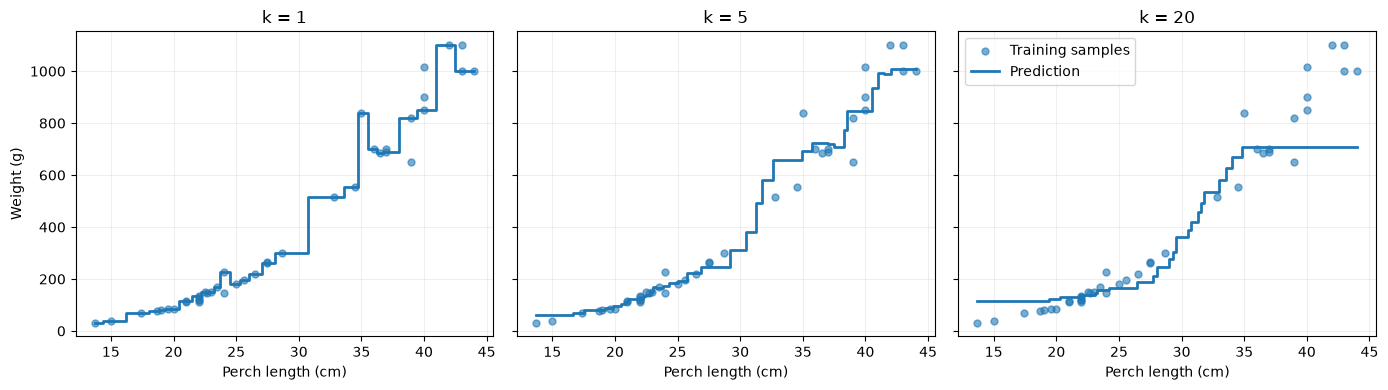

In [5]:
import matplotlib.pyplot as plt

# 훈련 데이터 길이 범위를 500개 지점으로 나누기
x_grid = np.linspace(
    train_input.min(), train_input.max(), 500
).reshape(-1, 1)

# 비교할 이웃 수
plot_ks = [1, 5, 20]

fig, axes = plt.subplots(
    1, 3, figsize=(14, 4),
    sharex=True, sharey=True
)

for ax, k in zip(axes, plot_ks):
    knn_plot = KNeighborsRegressor(n_neighbors=k)
    knn_plot.fit(train_input, train_target)

    # 각 길이에서 예측한 무게
    y_grid = knn_plot.predict(x_grid)

    # 실제 훈련 농어
    ax.scatter(
        train_input[:, 0], train_target,
        s=25, alpha=0.6, label="Training samples"
    )
    # KNN 회귀 예측선
    ax.step(
        x_grid[:, 0], y_grid,
        where="mid", linewidth=2, label="Prediction"
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Perch length (cm)")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Weight (g)")
axes[-1].legend(loc="upper left")
plt.tight_layout()
plt.show()

### 2단계. 그래프 해석하기

- **k=1**: 가장 가까운 농어 한 마리의 무게를 사용하므로 예측선이 불규칙하게 변합니다.
- **k=5**: 가까운 농어 5마리의 평균을 사용하기 때문에 개별 농어의 영향이 줄어듭니다.
- **k=20**: 더 넓은 범위의 농어를 평균 내면서 예측값의 변화가 완화됩니다. 다만 가까운 농어들의 특징을 충분히 반영하지 못할 수도 있습니다.

**예측선이 계단 모양인 이유**: 입력 길이가 조금 달라져도 선택되는 이웃이 같으면 예측값도 같고, 이웃이 바뀌는 순간 평균 무게가 달라져 예측값이 갑자기 변하기 때문입니다.

### 3단계. 학생 응용 실습

위 코드의 `plot_ks = [1, 5, 20]`을 `plot_ks = [3, 5, 10]`으로 바꾸고 다시 실행해 세 모델의 예측선을 비교해 보세요.

* **완료 확인**: 세 패널이 한 그림에 나란히 표시되고, k=1 패널의 예측선이 가장 들쭉날쭉하며 k=20 패널이 가장 완만합니다.